### Data Preprocessing

To build a stable text classification model with good generalization ability, we applied a unified preprocessing pipeline to two datasets:

1. AI Text Detection Pile  
2. HC3 dataset  


#### 1. Data Loading and Format Standardization

Both datasets were loaded from locally cached parquet files to improve efficiency.  
Since the original data formats were different, they were converted into a unified structure with the following fields:

- `text`: input text  
- `label`: class label (`0 = human-written text`, `1 = AI-generated text`)

After standardization, the two datasets were merged into a single dataset to improve the model’s generalization across different data sources.


#### 2. Label Standardization

To ensure consistency, the labels were unified as follows:

- Human-written text → 0  
- AI-generated text → 1  

This standardization guarantees that the label meanings remain consistent across different datasets.


#### 3. Data Cleaning

To improve data quality, several basic cleaning steps were applied:

- remove missing values (NaN)  
- remove empty texts  
- strip leading and trailing whitespace  
- remove duplicate samples based on text content  

These operations help reduce noise and prevent potential data leakage during training.


#### 4. Dataset Merging

After cleaning, the two datasets were combined into a single dataset.  
At the same time, a `dataset` field was retained to indicate the data source (for example, `ai_dataset` or `hc3_dataset`), which allows later analysis of model performance across different datasets.


#### 5. Dataset Splitting

The merged dataset was split into:

- 70% training set  
- 15% validation set  
- 15% test set  

A stratified split was used to ensure that the label distribution remained consistent across all subsets.


#### 6. Data Storage

To improve efficiency and reproducibility, the processed datasets were saved in parquet format:

- `train.parquet`
- `val.parquet`
- `test.parquet`

This approach avoids repeated preprocessing and significantly speeds up subsequent experiments.

In [2]:
import os
import json
import pandas as pd

file_path = "data/hc3_dataset.parquet"

if os.path.exists(file_path):
    print("Loading HC3 from local parquet file...")
    df2 = pd.read_parquet(file_path)

else:
    print("Processing HC3 dataset...")

    data = []

    with open("data/all.jsonl", "r", encoding="utf-8") as f:
        for line in f:
            item = json.loads(line)

            # human = 0
            for h in item["human_answers"]:
                data.append({"text": h, "label": 0})

            # ai = 1
            for ai in item["chatgpt_answers"]:
                data.append({"text": ai, "label": 1})

    df2 = pd.DataFrame(data)

    os.makedirs("data", exist_ok=True)
    df2.to_parquet(file_path, index=False)
    print("HC3 saved to local parquet file.")

print(df2.head(3))
print("Shape:", df2.shape)

Processing HC3 dataset...
HC3 saved to local parquet file.
                                                text  label
0  Basically there are many categories of " Best ...      0
1  If you 're hearing about it , it 's because it...      0
2  One reason is lots of catagories . However , h...      0
Shape: (85449, 2)


In [4]:
import os
import json
import pandas as pd

file_path = "data/hc3_dataset.parquet"

if os.path.exists(file_path):
    print("Loading HC3 from local parquet file...")
    df2 = pd.read_parquet(file_path)

else:
    print("Processing HC3 dataset...")

    data = []

    with open("data/all.jsonl", "r", encoding="utf-8") as f:
        for line in f:
            item = json.loads(line)

            # human = 0
            for h in item["human_answers"]:
                data.append({"text": h, "label": 0})

            # ai = 1
            for ai in item["chatgpt_answers"]:
                data.append({"text": ai, "label": 1})

    df2 = pd.DataFrame(data)

    os.makedirs("data", exist_ok=True)
    df2.to_parquet(file_path, index=False)
    print("HC3 saved to local parquet file.")

print(df2.head(3))
print("Shape:", df2.shape)

Loading HC3 from local parquet file...
                                                text  label
0  Basically there are many categories of " Best ...      0
1  If you 're hearing about it , it 's because it...      0
2  One reason is lots of catagories . However , h...      0
Shape: (85449, 2)


In [5]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# =========================
# 1. Path settings
# =========================
ai_path = "data/ai_dataset.parquet"
hc3_path = "data/hc3_dataset.parquet"

# Check whether the files exist
if not os.path.exists(ai_path):
    raise FileNotFoundError(f"File not found: {ai_path}")

if not os.path.exists(hc3_path):
    raise FileNotFoundError(f"File not found: {hc3_path}")

# =========================
# 2. Load the two parquet datasets
# =========================
print("Loading parquet files...")
df1 = pd.read_parquet(ai_path)
df2 = pd.read_parquet(hc3_path)

print("Dataset 1 shape:", df1.shape)
print("Dataset 2 shape:", df2.shape)

# =========================
# 3. Keep only the required columns
# =========================
df1 = df1[["text", "label"]].copy()
df2 = df2[["text", "label"]].copy()

# Optional: keep source information for later analysis
df1["dataset"] = "ai_dataset"
df2["dataset"] = "hc3_dataset"

# =========================
# 4. Merge the datasets
# =========================
df_all = pd.concat([df1, df2], ignore_index=True)

print("\nMerged shape before cleaning:", df_all.shape)
df_before_clean = df_all.copy()

# =========================
# 5. Basic data cleaning
# =========================
# Remove missing values
df_all = df_all.dropna(subset=["text", "label"])

# Convert text to string and strip leading/trailing whitespace
df_all["text"] = df_all["text"].astype(str).str.strip()

# Remove empty texts
df_all = df_all[df_all["text"] != ""]

# Convert labels to integer format
df_all["label"] = df_all["label"].astype(int)

# Remove duplicate samples based on text
df_all = df_all.drop_duplicates(subset="text").reset_index(drop=True)

print("Merged shape after cleaning:", df_all.shape)

# =========================
# 6. Check label and source distributions
# =========================
print("\nOverall label distribution:")
print(df_all["label"].value_counts())

print("\nDataset source distribution:")
print(df_all["dataset"].value_counts())

# =========================
# 7. Train / validation / test split
# Ratio: 70 / 15 / 15
# =========================
train_df, temp_df = train_test_split(
    df_all,
    test_size=0.30,
    random_state=42,
    stratify=df_all["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("\nTrain shape:", train_df.shape)
print(train_df["label"].value_counts())

print("\nValidation shape:", val_df.shape)
print(val_df["label"].value_counts())

print("\nTest shape:", test_df.shape)
print(test_df["label"].value_counts())

os.makedirs("data/splits", exist_ok=True)

train_df.to_parquet("data/splits/train.parquet", index=False)
val_df.to_parquet("data/splits/val.parquet", index=False)
test_df.to_parquet("data/splits/test.parquet", index=False)

print("\nSaved files:")
print("data/splits/train.parquet")
print("data/splits/val.parquet")
print("data/splits/test.parquet")

Loading parquet files...
Dataset 1 shape: (1392522, 2)
Dataset 2 shape: (85449, 2)

Merged shape before cleaning: (1477971, 3)
Merged shape after cleaning: (1407894, 3)

Overall label distribution:
label
0    1035679
1     372215
Name: count, dtype: int64

Dataset source distribution:
dataset
ai_dataset     1385793
hc3_dataset      22101
Name: count, dtype: int64

Train shape: (985525, 3)
label
0    724975
1    260550
Name: count, dtype: int64

Validation shape: (211184, 3)
label
0    155352
1     55832
Name: count, dtype: int64

Test shape: (211185, 3)
label
0    155352
1     55833
Name: count, dtype: int64

Saved files:
data/splits/train.parquet
data/splits/val.parquet
data/splits/test.parquet



Summary comparison:
             Stage  Samples  Human (0)  AI (1)  AI Dataset  HC3 Dataset
0  Before Cleaning  1477971    1086692  391279     1392522        85449
1   After Cleaning  1407894    1035679  372215     1385793        22101


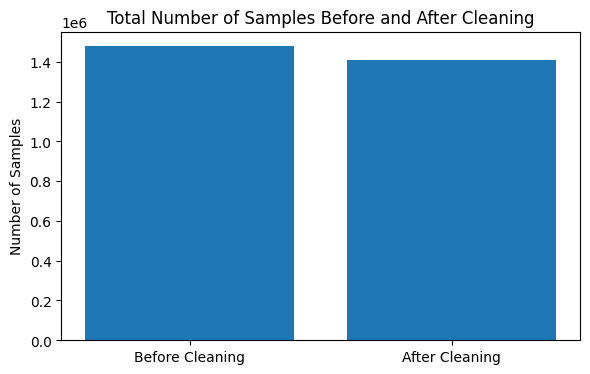

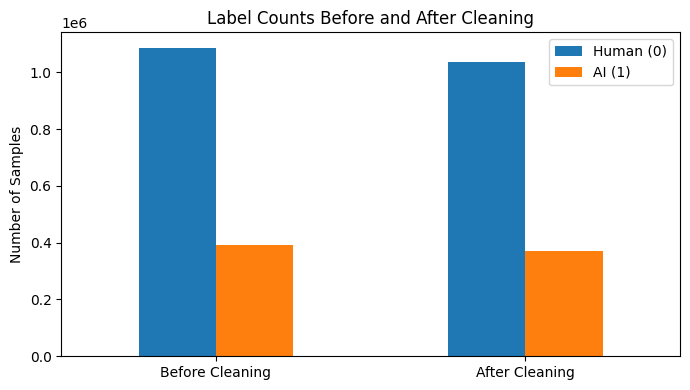

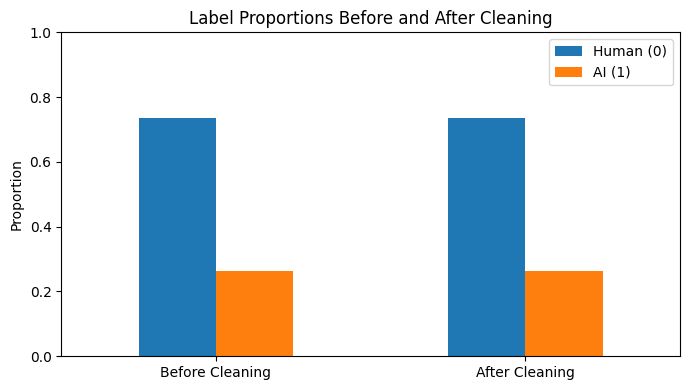

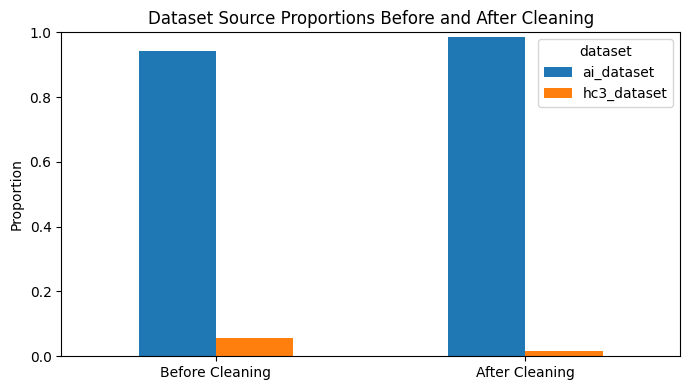

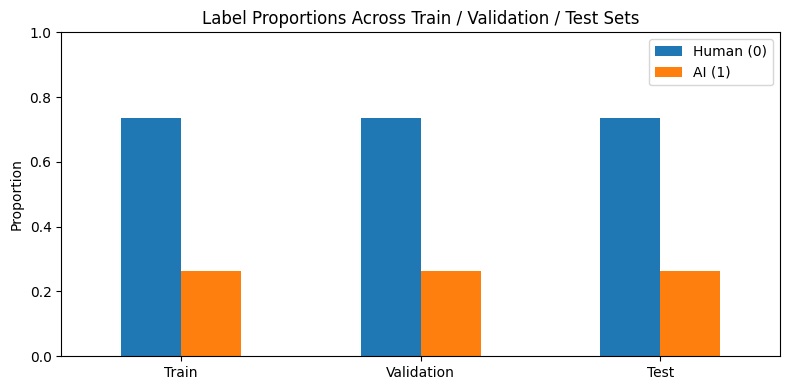

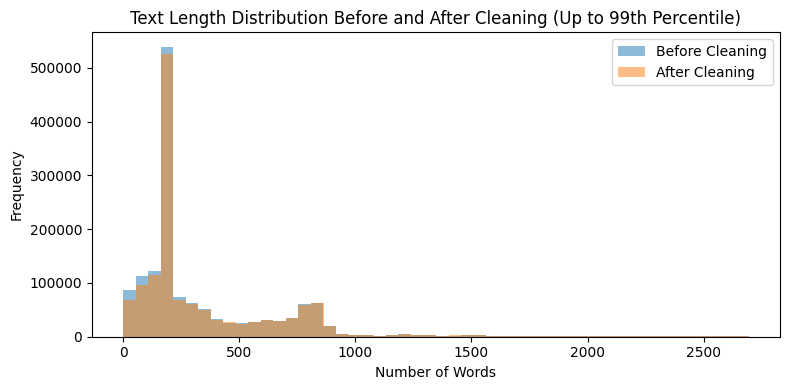


Label proportions before cleaning:
label
0    0.735259
1    0.264741
Name: proportion, dtype: float64

Label proportions after cleaning:
label
0    0.735623
1    0.264377
Name: proportion, dtype: float64

Dataset source proportions before cleaning:
dataset
ai_dataset     0.942185
hc3_dataset    0.057815
Name: proportion, dtype: float64

Dataset source proportions after cleaning:
dataset
ai_dataset     0.984302
hc3_dataset    0.015698
Name: proportion, dtype: float64

Label proportions in train / validation / test:
            Human (0)    AI (1)
Train        0.735623  0.264377
Validation   0.735624  0.264376
Test         0.735620  0.264380


In [7]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# =========================
# 8. Reconstruct the dataset before cleaning for visualization
# =========================
df1_plot = pd.read_parquet(ai_path)[["text", "label"]].copy()
df2_plot = pd.read_parquet(hc3_path)[["text", "label"]].copy()

df1_plot["dataset"] = "ai_dataset"
df2_plot["dataset"] = "hc3_dataset"

df_before_clean = pd.concat([df1_plot, df2_plot], ignore_index=True)

# Standardize basic format for fair comparison
df_before_clean = df_before_clean.dropna(subset=["text", "label"]).copy()
df_before_clean["text"] = df_before_clean["text"].astype(str).str.strip()
df_before_clean["label"] = df_before_clean["label"].astype(int)

# Use the cleaned dataset from the previous step
df_after_clean = df_all.copy()

# =========================
# 9. Basic statistics for comparison
# =========================
summary_df = pd.DataFrame({
    "Stage": ["Before Cleaning", "After Cleaning"],
    "Samples": [len(df_before_clean), len(df_after_clean)],
    "Human (0)": [
        (df_before_clean["label"] == 0).sum(),
        (df_after_clean["label"] == 0).sum()
    ],
    "AI (1)": [
        (df_before_clean["label"] == 1).sum(),
        (df_after_clean["label"] == 1).sum()
    ],
    "AI Dataset": [
        (df_before_clean["dataset"] == "ai_dataset").sum(),
        (df_after_clean["dataset"] == "ai_dataset").sum()
    ],
    "HC3 Dataset": [
        (df_before_clean["dataset"] == "hc3_dataset").sum(),
        (df_after_clean["dataset"] == "hc3_dataset").sum()
    ]
})

print("\nSummary comparison:")
print(summary_df)

# =========================
# 10. Plot 1: total sample counts before vs after cleaning
# =========================
plt.figure(figsize=(6, 4))
plt.bar(summary_df["Stage"], summary_df["Samples"])
plt.title("Total Number of Samples Before and After Cleaning")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# =========================
# 11. Plot 2: label counts before vs after cleaning
# =========================
label_compare = pd.DataFrame({
    "Before Cleaning": df_before_clean["label"].value_counts().sort_index(),
    "After Cleaning": df_after_clean["label"].value_counts().sort_index()
}).T

label_compare.columns = ["Human (0)", "AI (1)"]

label_compare.plot(kind="bar", figsize=(7, 4))
plt.title("Label Counts Before and After Cleaning")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# =========================
# 12. Plot 3: label proportions before vs after cleaning
# =========================
label_prop_compare = pd.DataFrame({
    "Before Cleaning": df_before_clean["label"].value_counts(normalize=True).sort_index(),
    "After Cleaning": df_after_clean["label"].value_counts(normalize=True).sort_index()
}).T

label_prop_compare.columns = ["Human (0)", "AI (1)"]

label_prop_compare.plot(kind="bar", figsize=(7, 4))
plt.title("Label Proportions Before and After Cleaning")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# =========================
# 13. Plot 4: dataset source proportions before vs after cleaning
# =========================
source_prop_compare = pd.DataFrame({
    "Before Cleaning": df_before_clean["dataset"].value_counts(normalize=True),
    "After Cleaning": df_after_clean["dataset"].value_counts(normalize=True)
}).T

source_prop_compare = source_prop_compare[["ai_dataset", "hc3_dataset"]]

source_prop_compare.plot(kind="bar", figsize=(7, 4))
plt.title("Dataset Source Proportions Before and After Cleaning")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# =========================
# 14. Plot 5: label proportions across train / validation / test
# =========================
split_label_prop_df = pd.DataFrame({
    "Train": train_df["label"].value_counts(normalize=True).sort_index(),
    "Validation": val_df["label"].value_counts(normalize=True).sort_index(),
    "Test": test_df["label"].value_counts(normalize=True).sort_index()
}).T

split_label_prop_df.columns = ["Human (0)", "AI (1)"]

split_label_prop_df.plot(kind="bar", figsize=(8, 4))
plt.title("Label Proportions Across Train / Validation / Test Sets")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# =========================
# 15. Plot 6 (optional): text length distribution with outlier control
# =========================
df_before_clean["text_length"] = df_before_clean["text"].apply(lambda x: len(str(x).split()))
df_after_clean["text_length"] = df_after_clean["text"].apply(lambda x: len(str(x).split()))

upper_bound = max(
    df_before_clean["text_length"].quantile(0.99),
    df_after_clean["text_length"].quantile(0.99)
)

plt.figure(figsize=(8, 4))
plt.hist(
    df_before_clean[df_before_clean["text_length"] <= upper_bound]["text_length"],
    bins=50,
    alpha=0.5,
    label="Before Cleaning"
)
plt.hist(
    df_after_clean[df_after_clean["text_length"] <= upper_bound]["text_length"],
    bins=50,
    alpha=0.5,
    label="After Cleaning"
)
plt.title("Text Length Distribution Before and After Cleaning (Up to 99th Percentile)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 16. Optional: display key percentages for reporting
# =========================
print("\nLabel proportions before cleaning:")
print(df_before_clean["label"].value_counts(normalize=True).sort_index())

print("\nLabel proportions after cleaning:")
print(df_after_clean["label"].value_counts(normalize=True).sort_index())

print("\nDataset source proportions before cleaning:")
print(df_before_clean["dataset"].value_counts(normalize=True))

print("\nDataset source proportions after cleaning:")
print(df_after_clean["dataset"].value_counts(normalize=True))

print("\nLabel proportions in train / validation / test:")
print(split_label_prop_df)